# CodeLab RSI: Do target networks help an RL-driven program optimizer?
**Colab T4 reproducible experiment · October 2026**

This is a *bounded recursive program-improvement* experiment, **not** a foundation-model RSI system. A policy chooses edits to a real k-nearest-neighbor search implementation, and each edited implementation is checked for correctness and benchmarked. DQN agents learn from the transition/reward history; no LLM generates code.

**Research question:** Given an identical budget of five candidate edits, do target networks, Double DQN, and dueling/soft updates improve held-out runtime gains over random editing and online-only DQN?

**Design:** Benchmark 24 executable program configurations on four calibration workloads, train RL controllers exclusively using this measured calibration table, freeze models, then evaluate once on three different workload sizes. The correctness oracle is an independent NumPy float64 implementation; invalid candidates cannot be accepted. Per-seed paired results and all failures are reported. This deliberately scopes down Eureka/Darwin-Gödel-Machine style programs and is not a claim of agent self-rewriting.

**Important limitations:** measurements are CPU NumPy kernels, while network training uses the Colab T4; measured rewards are cached rather than rebenchmarking every rollout; the search space is template-based, finite, and hand-authored. Benchmarks on a shared Colab VM can be noisy.

Inspired by [DQN](https://arxiv.org/abs/1312.5602), [Double DQN](https://arxiv.org/abs/1509.06461), [Dueling DQN](https://arxiv.org/abs/1511.06581), and recent [RRSI](https://arxiv.org/abs/2609.24972).

## 1. Real executable program variants and correctness/latency calibration

In [1]:
import numpy as np, torch, pandas as pd, itertools, time, hashlib, json, os, random
import torch.nn as nn
from collections import deque
from scipy.stats import wilcoxon
torch.set_num_threads(1)
print("Execution:",torch.__version__,"CUDA",torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
CONFIGS=list(itertools.product(range(3),range(2),range(2),range(2)))
TRAIN_SHAPES=[(16,320,24,5),(24,480,32,7),(32,700,40,9),(40,960,28,11)]
TEST_SHAPES=[(18,400,48,6),(36,1050,56,10),(48,1450,64,13)]
BASE=(0,0,1,0)
def make_input(shape,seed):
    nquery,ntrain,dim,k=shape
    rng=np.random.default_rng(seed)
    return rng.normal(size=(nquery,dim)).astype("float32"),rng.normal(size=(ntrain,dim)).astype("float32"),k

def neighbors(x,t,k,config):
    method,selection,dtype_id,chunk_id=config
    dtype=np.float32 if dtype_id==0 else np.float64
    x=x.astype(dtype,copy=False);t=t.astype(dtype,copy=False)
    if method==0: # naive broadcast
        d2=((x[:,None,:]-t[None,:,:])**2).sum(axis=2)
    elif method==1: # matrix multiplication identity
        d2=np.maximum(np.sum(x*x,axis=1)[:,None]+np.sum(t*t,axis=1)[None,:]-2*x@t.T,0)
    else: # memory-bounded matrix multiply, avoids giant temporary broadcast
        block=32 if chunk_id==0 else 128
        d2=np.empty((len(x),len(t)),dtype=dtype)
        tn=np.sum(t*t,axis=1)
        for a in range(0,len(x),block):
            z=x[a:a+block]
            d2[a:a+block]=np.maximum(np.sum(z*z,axis=1)[:,None]+tn[None,:]-2*z@t.T,0)
    if selection==0:
        return np.argsort(d2,axis=1)[:,:k]
    ix=np.argpartition(d2,kth=k-1,axis=1)[:,:k]
    return np.take_along_axis(ix,np.argsort(np.take_along_axis(d2,ix,axis=1),axis=1),axis=1)

def bench_group(shapes,tag):
    rows=[]
    for idx,shape in enumerate(shapes):
        x,t,k=make_input(shape,1000+idx if tag=="calibration" else 6000+idx)
        reference=neighbors(x,t,k,(0,0,1,0))
        for conf in CONFIGS:
            error=""
            try:
                actual=neighbors(x,t,k,conf)
                good=bool(np.array_equal(actual,reference))
                neighbors(x,t,k,conf)
                values=[]
                for rep in range(3):
                    start=time.perf_counter()
                    neighbors(x,t,k,conf)
                    values.append((time.perf_counter()-start)*1000)
                ms=float(np.median(values))
            except Exception as e:
                good=False;ms=float("nan");error=repr(e)
            rows.append(dict(split=tag,shape_id=idx,shape=str(shape),config=":".join(map(str,conf)),valid=good,latency_ms=ms,error=error))
    return pd.DataFrame(rows)
cal=bench_group(TRAIN_SHAPES,"calibration")
print("CALIBRATION correctness",int(cal.valid.sum()),"/",len(cal),
      "invalid",int((~cal.valid).sum()))
if not cal.valid.all():print(cal.loc[~cal.valid].to_string(index=False))
assert cal.valid.all(), "Correctness gate: invalid program variant detected"
cal.to_csv("/content/codelab_calibration.csv",index=False)
def lookup(table):
    return {(int(r.shape_id),tuple(map(int,r.config.split(":")))):float(r.latency_ms) for r in table.itertuples()}
CAL=lookup(cal)


Execution: 2.11.0+cu130 CUDA True Tesla T4
CALIBRATION correctness 96 / 96 invalid 0


## 2. RL agent: state = workload + current code configuration; action = code edit; reward = measured runtime change
All variants use the same replay buffer policy and training budget. Online-only bootstraps on itself, hard-target DQN uses a delayed target, Double DQN decouples argmax from evaluation, and dueling Double DQN adds mean-centered advantage plus EMA updates.

In [2]:
ACTIONS=6
def edit(conf,action):
    m,s,d,c=conf
    if action==0:m=(m+1)%3
    elif action==1:m=(m-1)%3
    elif action==2:s^=1
    elif action==3:d^=1
    elif action==4:c^=1
    elif action==5:m=(m+1)%3;s^=1
    return (m,s,d,c)
def state(shape,conf,remaining):
    q,n,dim,k=shape
    return np.array([np.log1p(q)/6,np.log1p(n)/8,np.log1p(dim)/6,
         k/20, conf[0]/2,conf[1],conf[2],conf[3],remaining/5],dtype=np.float32)
class QNet(nn.Module):
    def __init__(self,dueling=False):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(9,48),nn.ReLU(),nn.Linear(48,48),nn.ReLU())
        self.dueling=dueling
        if dueling:
            self.v=nn.Linear(48,1);self.a=nn.Linear(48,ACTIONS)
        else:self.q=nn.Linear(48,ACTIONS)
    def forward(self,x):
        z=self.net(x)
        if self.dueling:
            a=self.a(z);return self.v(z)+a-a.mean(dim=1,keepdim=True)
        return self.q(z)
class Learner:
    def __init__(self,kind,seed):
        torch.manual_seed(seed);np.random.seed(seed);random.seed(seed)
        self.kind=kind
        dueling=kind=="dueling_double_soft"
        self.q=QNet(dueling).to(DEVICE)
        self.t=QNet(dueling).to(DEVICE)
        self.t.load_state_dict(self.q.state_dict())
        self.opt=torch.optim.Adam(self.q.parameters(),lr=.001)
        self.replay=deque(maxlen=5000);self.rng=np.random.default_rng(seed+123)
        self.updates=0
    def action(self,s,eps):
        if self.rng.random()<eps:return int(self.rng.integers(ACTIONS))
        with torch.no_grad():
            return int(self.q(torch.from_numpy(s)[None].to(DEVICE)).argmax(dim=1).item())
    def learn(self,batchsize=32):
        if len(self.replay)<batchsize:return
        ix=self.rng.integers(len(self.replay),size=batchsize)
        z=[self.replay[int(i)] for i in ix]
        s=torch.as_tensor(np.array([v[0] for v in z]),device=DEVICE)
        a=torch.as_tensor([v[1] for v in z],device=DEVICE).long()
        r=torch.as_tensor([v[2] for v in z],device=DEVICE).float()
        nexts=torch.as_tensor(np.array([v[3] for v in z]),device=DEVICE)
        done=torch.as_tensor([v[4] for v in z],device=DEVICE).float()
        q=self.q(s).gather(1,a[:,None]).squeeze(1)
        with torch.no_grad():
            if self.kind=="online_only":
                nextval=self.q(nexts).max(1).values
            elif self.kind=="dqn_hard":
                nextval=self.t(nexts).max(1).values
            else:
                greed=self.q(nexts).argmax(1,keepdim=True)
                nextval=self.t(nexts).gather(1,greed).squeeze(1)
            target=r+.95*(1-done)*nextval
        loss=nn.functional.smooth_l1_loss(q,target)
        self.opt.zero_grad();loss.backward();nn.utils.clip_grad_norm_(self.q.parameters(),5);self.opt.step()
        self.updates+=1
        if self.kind=="dueling_double_soft":
            with torch.no_grad():
                for tt,oo in zip(self.t.parameters(),self.q.parameters()):
                    tt.mul_(.98).add_(oo,alpha=.02)
        elif self.updates%45==0:self.t.load_state_dict(self.q.state_dict())
def step(shape_idx,conf,action,table):
    prop=edit(conf,action)
    c=table[(shape_idx,conf)];p=table[(shape_idx,prop)]
    accepted=(p<c)
    reward=float(np.clip(np.log(c/p),-.8,.8))
    return (prop if accepted else conf),reward,accepted
def train_agent(kind,seed,episodes=75):
    agent=Learner(kind,seed)
    curves=[]
    for ep in range(episodes):
        shape_id=(ep+seed)%len(TRAIN_SHAPES)
        conf=BASE
        for j in range(5):
            s=state(TRAIN_SHAPES[shape_id],conf,5-j)
            a=agent.action(s,eps=max(.08,.42*(1-ep/episodes)))
            conf2,r,ok=step(shape_id,conf,a,CAL)
            nexts=state(TRAIN_SHAPES[shape_id],conf2,4-j)
            agent.replay.append((s,a,r,nexts,j==4))
            agent.learn()
            conf=conf2
        curves.append(float(CAL[(shape_id,BASE)]/CAL[(shape_id,conf)]))
    return agent,curves
METHODS=["online_only","dqn_hard","double_dqn_hard","dueling_double_soft"]
SEEDS=list(range(6))
print("Methods",METHODS,"training seeds",SEEDS,"episodes per seed 75")


Methods ['online_only', 'dqn_hard', 'double_dqn_hard', 'dueling_double_soft'] training seeds [0, 1, 2, 3, 4, 5] episodes per seed 75


In [3]:
AGENTS={};CURVES={}
for kind in METHODS[:2]:
    for seed in SEEDS:
        agent,curve=train_agent(kind,seed)
        AGENTS[(kind,seed)]=agent
        CURVES[(kind,seed)]=curve
    print("trained",kind,"n",len(SEEDS),"mean last-10 train speedup",
          round(float(np.mean([np.mean(CURVES[(kind,s)][-10:]) for s in SEEDS])),3))


trained online_only n 6 mean last-10 train speedup 6.461
trained dqn_hard n 6 mean last-10 train speedup 6.479


In [4]:
for kind in METHODS[2:]:
    for seed in SEEDS:
        agent,curve=train_agent(kind,seed)
        AGENTS[(kind,seed)]=agent
        CURVES[(kind,seed)]=curve
    print("trained",kind,"n",len(SEEDS),"mean last-10 train speedup",
          round(float(np.mean([np.mean(CURVES[(kind,s)][-10:]) for s in SEEDS])),3))


trained double_dqn_hard n 6 mean last-10 train speedup 6.49
trained dueling_double_soft n 6 mean last-10 train speedup 6.597


## 3. One-time held-out benchmark and paired evaluation
There is no replay-tuning on test workloads. The optimizer's candidate implementations are correctness-checked before any speed results are analyzed. Random uses the same five-edit limit.

In [5]:
# Held-out task shapes have NEVER appeared during training or model selection.
heldout=bench_group(TEST_SHAPES,"heldout")
assert heldout.valid.all(), "Heldout correctness gate failed"
TEST=lookup(heldout)
heldout.to_csv("/content/codelab_heldout_measurements.csv",index=False)
print("HELDOUT correctness",int(heldout.valid.sum()),"/",len(heldout))
rows=[]
for seed in SEEDS:
    for idx,shape in enumerate(TEST_SHAPES):
        for kind in ["random",*METHODS]:
            conf=BASE; accepted=0
            rng=np.random.default_rng(seed*991+idx*31+5)
            for j in range(5):
                if kind=="random":a=int(rng.integers(ACTIONS))
                else:a=AGENTS[(kind,seed)].action(state(shape,conf,5-j),0.0)
                conf,reward,ok=step(idx,conf,a,TEST)
                accepted+=int(ok)
            baseline=TEST[(idx,BASE)]
            result=TEST[(idx,conf)]
            rows.append(dict(seed=seed,method=kind,heldout_shape=idx,baseline_ms=baseline,
                       final_ms=result,speedup=baseline/result,log_speedup=np.log(baseline/result),
                       accepted_edits=accepted,final_config=str(conf)))
results=pd.DataFrame(rows)
results.to_csv("/content/codelab_heldout_results.csv",index=False)
print("RUNS",len(results),"rows; six paired seeds x three shapes x five methods")
summary=results.groupby("method").agg(mean_speedup=("speedup","mean"),
    geometric_speedup=("log_speedup",lambda x: float(np.exp(x.mean()))),
    mean_accepted_edits=("accepted_edits","mean")).sort_values("geometric_speedup",ascending=False)
print(summary.round(3).to_string())
seeded=results.groupby(["seed","method"])["log_speedup"].mean().unstack()
for m in METHODS:
    d=seeded[m]-seeded["random"]
    p=float(wilcoxon(d).pvalue) if np.any(np.abs(d)>1e-12) else 1.0
    print("PAIRED",m,"delta loggain vs random",round(float(d.mean()),4),
         "p_unadjusted",round(p,5),"n_seeds",len(d))


HELDOUT correctness 72 / 72
RUNS 90 rows; six paired seeds x three shapes x five methods
                     mean_speedup  geometric_speedup  mean_accepted_edits
method                                                                   
online_only                15.469             12.377                3.667
dqn_hard                   15.459             12.258                3.500
double_dqn_hard            15.375             12.205                3.222
dueling_double_soft        14.900             12.018                3.444
random                     13.037             10.224                2.833
PAIRED online_only delta loggain vs random 0.1911 p_unadjusted 0.0625 n_seeds 6
PAIRED dqn_hard delta loggain vs random 0.1814 p_unadjusted 0.0625 n_seeds 6
PAIRED double_dqn_hard delta loggain vs random 0.1771 p_unadjusted 0.0625 n_seeds 6
PAIRED dueling_double_soft delta loggain vs random 0.1616 p_unadjusted 0.15625 n_seeds 6


COLAB_ARTIFACTS ["/content/codelab_calibration.csv", "/content/codelab_heldout_measurements.csv", "/content/codelab_heldout_results.csv", "/content/codelab_heldout.png", "/content/codelab_learning_curves.png"]


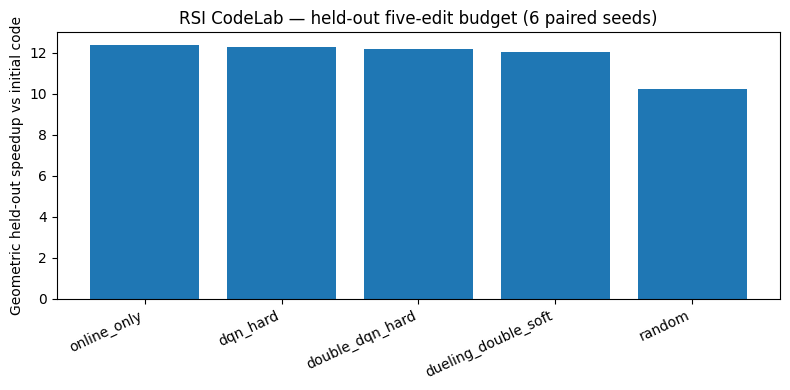

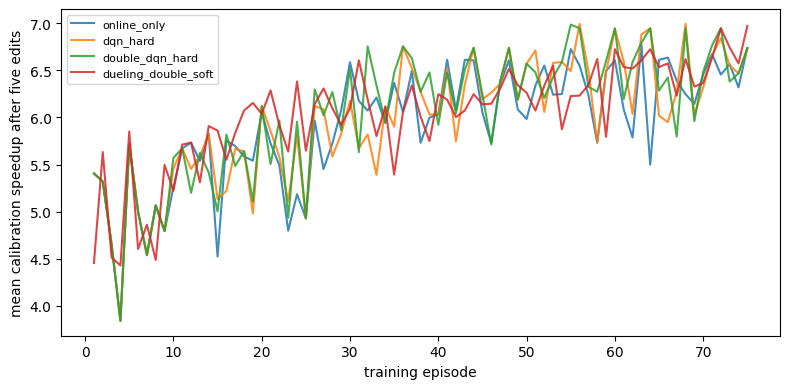

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
names=summary.index.tolist()
plt.bar(names,summary.geometric_speedup.to_numpy())
plt.xticks(rotation=25,ha="right");plt.ylabel("Geometric held-out speedup vs initial code")
plt.title("RSI CodeLab — held-out five-edit budget (6 paired seeds)")
plt.tight_layout();plt.savefig("/content/codelab_heldout.png",dpi=160);plt.show()
plt.figure(figsize=(8,4))
for m in METHODS:
    a=np.asarray([CURVES[(m,s)] for s in SEEDS],dtype=float)
    plt.plot(np.arange(a.shape[1])+1,a.mean(axis=0),label=m,alpha=.85)
plt.xlabel("training episode");plt.ylabel("mean calibration speedup after five edits")
plt.legend(fontsize=8);plt.tight_layout()
plt.savefig("/content/codelab_learning_curves.png",dpi=160);plt.show()
print("COLAB_ARTIFACTS",json.dumps(["/content/codelab_calibration.csv",
 "/content/codelab_heldout_measurements.csv","/content/codelab_heldout_results.csv",
 "/content/codelab_heldout.png","/content/codelab_learning_curves.png"]))


## Interpretation and limitations
If effect sizes are small or non-significant, conclude **no established superiority**; do not claim frontier-model RSI, autonomous LLM rewriting, or benchmark-level advances. Training treats empirically profiled program runtimes as a deterministic reward table, so it isolates search/controller mechanics. Profiling the entire finite candidate space up front is unrealistic for large self-improvement; the method tests controller selection, not hypothesis generation. CPU benchmark timings may differ across Colab hardware. RRSI is a related harness-evolution paper, but this is **not** a reproduction or comparison to its complete algorithm.